In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
import joblib

df = pd.read_excel('E20_predictions_final.xlsx')
df.head() 

########## EDA


,Brand,Model,Variant,Engine (CC),Mileage Claimed (km/L),Mileage Tested (km/L),Launch Year,Launch Year Note,E20 Compatible,E20_Drop_%,Mileage_E20_Estimated
0,Citroen,Aircross X (C3 Aircross),1.2L Petrol (NA),1198.0,19.3,16.4,2024,NaN,Yes,4.0,15.744
1,Citroen,Aircross X (C3 Aircross),1.2L Turbo Petrol,1199.0,19.5,16.6,2024,NaN,Yes,4.0,15.936
2,Citroen,Basalt X,1.2L Turbo Petrol,1199.0,19.5,16.6,2024,NaN,Yes,4.0,15.936
3,Citroen,C3,1.2L Petrol (NA),1198.0,19.3,16.4,2022,NaN,Yes,4.0,15.744
4,Citroen,C3,1.2L Turbo Petrol,1199.0,19.5,16.6,2023,NaN,Yes,4.0,15.936


In [2]:
print(df.shape)
df.info()

(221, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Brand                   221 non-null    object 
 1   Model                   221 non-null    object 
 2   Variant                 221 non-null    object 
 3   Engine (CC)             217 non-null    float64
 4   Mileage Claimed (km/L)  208 non-null    float64
 5   Mileage Tested (km/L)   208 non-null    float64
 6   Launch Year             221 non-null    int64  
 7   Launch Year Note        2 non-null      object 
 8   E20 Compatible          221 non-null    object 
 9   E20_Drop_%              204 non-null    float64
 10  Mileage_E20_Estimated   202 non-null    float64
dtypes: float64(5), int64(1), object(5)
memory usage: 19.1+ KB


In [3]:
df.isna().sum()

Brand                       0
Model                       0
Variant                     0
Engine (CC)                 4
Mileage Claimed (km/L)     13
Mileage Tested (km/L)      13
Launch Year                 0
Launch Year Note          219
E20 Compatible              0
E20_Drop_%                 17
Mileage_E20_Estimated      19
dtype: int64

In [4]:
df['E20 Compatible'].value_counts()

E20 Compatible
Yes               119
No                 85
N/A (CNG)           7
N/A (Diesel)        7
TBA (Upcoming)      2
Discontinued        1
Name: count, dtype: int64

In [5]:
df['E20_Drop_%'].value_counts().sort_index()

E20_Drop_%
3.0    55
4.0    50
5.0    13
6.0    21
7.0    26
8.0    21
9.0    18
Name: count, dtype: int64

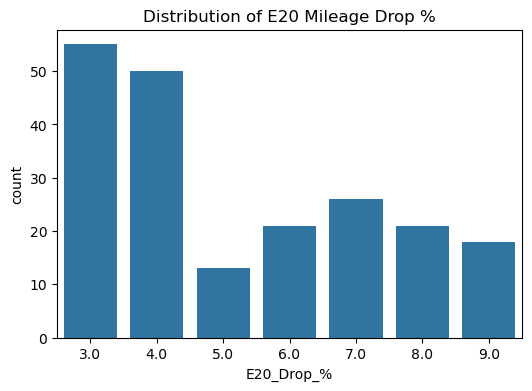

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='E20_Drop_%')
plt.title('Distribution of E20 Mileage Drop %')
plt.show()


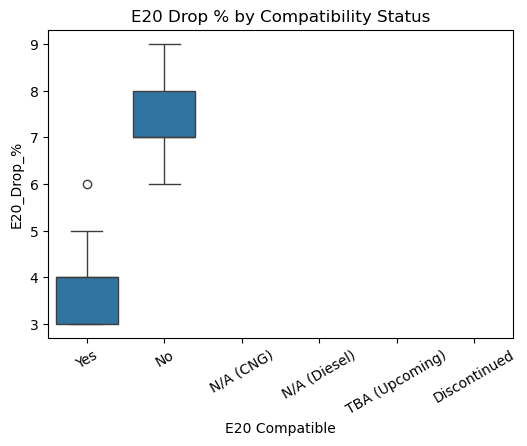

In [7]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='E20 Compatible', y='E20_Drop_%')
plt.xticks(rotation=30)
plt.title('E20 Drop % by Compatibility Status')
plt.show()


In [8]:
df[['Engine (CC)', 'Launch Year', 'E20_Drop_%']].corr()

,Engine (CC),Launch Year,E20_Drop_%
Engine (CC),1.000000,-0.000991,-0.256442
Launch Year,-0.000991,1.000000,-0.767500
E20_Drop_%,-0.256442,-0.767500,1.000000


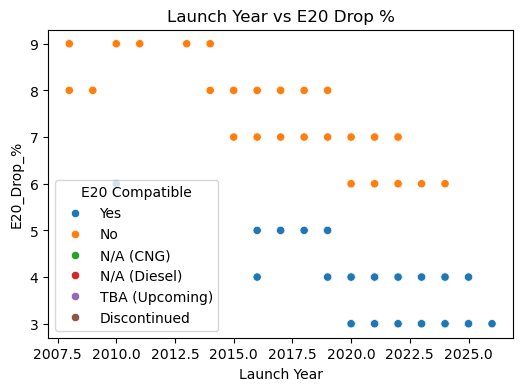

In [9]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x='Launch Year', y='E20_Drop_%', hue='E20 Compatible')
plt.title('Launch Year vs E20 Drop %')
plt.show()

In [10]:
##### FEATUR ENGINEERING

# Drop rows with missing target or key feature
model_df = df.dropna(subset=['E20_Drop_%', 'Engine (CC)']).copy()
print('Rows available for training:', len(model_df))

# Features: Engine CC, Launch Year, E20 Compatible (one-hot encoded)
X = model_df[['Engine (CC)', 'Launch Year', 'E20 Compatible']].copy()
X = pd.get_dummies(X, columns=['E20 Compatible'], drop_first=True)
model_columns = X.columns.tolist()
y = model_df['E20_Drop_%']

X.head()

Rows available for training: 204


,Engine (CC),Launch Year,E20 Compatible_Yes
0,1198.0,2024,True
1,1199.0,2024,True
2,1199.0,2024,True
3,1198.0,2022,True
4,1199.0,2023,True


In [11]:
#### TRAIN TEST SPLIT  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)


In [12]:
r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)
print('R2:', r2)
print('MAE:', mae)

R2: 0.9986464463397299
MAE: 0.028455284552845513


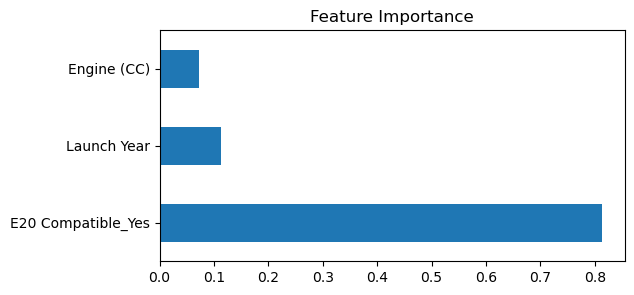

E20 Compatible_Yes    0.814140
Launch Year           0.112920
Engine (CC)           0.072941
dtype: float64

In [13]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.plot(kind='barh', figsize=(6,3), title='Feature Importance')
plt.show()
importances

In [14]:
joblib.dump(model, 'e20_drop_model.pkl')
joblib.dump(model_columns, 'model_columns.pkl')
print('Model and column mapping saved.')

Model and column mapping saved.


In [15]:
def predict_e20_drop(engine_cc, launch_year, e20_compatible, brand=None, model_obj=model, columns=model_columns):
    """
    Predicts E20 mileage drop % for a given car spec.

    Parameters:
        engine_cc (float): Engine displacement in CC
        launch_year (int): Year the car was launched
        e20_compatible (str): One of 'Yes', 'No', 'N/A (CNG)', 'N/A (Diesel)', 'TBA (Upcoming)', 'Discontinued'
        brand (str, optional): Not used in the model directly (not a training feature), kept for logging/display only
        model_obj: trained model (defaults to the RandomForest trained above)
        columns: training-time one-hot column order (defaults to model_columns)

    Returns:
        dict with predicted_drop_pct and a status flag for edge cases
    """
    warnings = []

    # --- Edge case: out-of-range engine CC ---
    if engine_cc < 600 or engine_cc > 3000:
        warnings.append(f"Engine CC ({engine_cc}) is outside the typical training range (600-3000cc). Prediction may be unreliable.")

    # --- Edge case: out-of-range launch year ---
    if launch_year < 2010 or launch_year > 2026:
        warnings.append(f"Launch Year ({launch_year}) is outside the training range (2010-2026). Prediction may be unreliable.")

    # --- Edge case: unknown/invalid compatibility label ---
    valid_labels = ['Yes', 'No', 'N/A (CNG)', 'N/A (Diesel)', 'TBA (Upcoming)', 'Discontinued']
    if e20_compatible not in valid_labels:
        return {
            "error": f"Invalid E20 Compatible value '{e20_compatible}'. Must be one of {valid_labels}.",
            "predicted_drop_pct": None
        }

    # --- Edge case: non-petrol / not-applicable cars ---
    if e20_compatible in ['N/A (CNG)', 'N/A (Diesel)']:
        return {
            "predicted_drop_pct": 0.0,
            "note": "E20 blending does not apply to this fuel type (CNG/Diesel). Drop is 0 by definition.",
            "warnings": warnings
        }

    # Build feature row matching training-time one-hot columns
    row = pd.DataFrame([{"Engine (CC)": engine_cc, "Launch Year": launch_year}])
    for col in columns:
        if col.startswith("E20 Compatible_"):
            label = col.replace("E20 Compatible_", "")
            row[col] = 1 if e20_compatible == label else 0
    row = row.reindex(columns=columns, fill_value=0)

    pred = model_obj.predict(row)[0]
    pred = float(np.clip(pred, 0, 15))  # sanity clip - drop % shouldn't realistically exceed this range

    result = {
        "brand": brand,
        "engine_cc": engine_cc,
        "launch_year": launch_year,
        "e20_compatible": e20_compatible,
        "predicted_drop_pct": round(pred, 2),
        "warnings": warnings
    }
    return result

# Quick test
predict_e20_drop(engine_cc=1200, launch_year=2022, e20_compatible="Yes", brand="Maruti Suzuki")


{'brand': 'Maruti Suzuki',
 'engine_cc': 1200,
 'launch_year': 2022,
 'e20_compatible': 'Yes',
 'predicted_drop_pct': 4.0,
 'warnings': []}

In [16]:
def estimate_monthly_cost(mileage_tested, monthly_km, price_per_litre, engine_cc, launch_year, e20_compatible, brand=None):
    """
    Full pipeline: predicts E20 drop, estimates E20 mileage, then computes monthly fuel cost
    for both regular petrol and E20 blend so the user can compare.

    Parameters:
        mileage_tested (float): Real-world tested mileage on regular petrol (km/L)
        monthly_km (float): User's expected monthly driving distance (km)
        price_per_litre (float): Current fuel price per litre (Rs)
        engine_cc, launch_year, e20_compatible, brand: passed to predict_e20_drop

    Returns:
        dict with mileage estimates and cost comparison
    """
    if monthly_km <= 0 or price_per_litre <= 0 or mileage_tested <= 0:
        return {"error": "monthly_km, price_per_litre, and mileage_tested must all be positive numbers."}

    drop_result = predict_e20_drop(engine_cc, launch_year, e20_compatible, brand)

    if drop_result.get("error"):
        return drop_result

    drop_pct = drop_result["predicted_drop_pct"]
    mileage_e20 = mileage_tested * (1 - drop_pct / 100)

    cost_petrol = (monthly_km / mileage_tested) * price_per_litre
    cost_e20 = (monthly_km / mileage_e20) * price_per_litre if mileage_e20 > 0 else None

    return {
        "brand": brand,
        "mileage_tested_petrol": round(mileage_tested, 2),
        "predicted_drop_pct": drop_pct,
        "estimated_mileage_e20": round(mileage_e20, 2) if mileage_e20 else None,
        "monthly_cost_petrol_rs": round(cost_petrol, 2),
        "monthly_cost_e20_rs": round(cost_e20, 2) if cost_e20 else None,
        "extra_monthly_cost_rs": round(cost_e20 - cost_petrol, 2) if cost_e20 else None,
        "warnings": drop_result.get("warnings", [])
    }

# Quick test
estimate_monthly_cost(
    mileage_tested=18.5,
    monthly_km=1200,
    price_per_litre=96.5,
    engine_cc=1200,
    launch_year=2022,
    e20_compatible="Yes",
    brand="Maruti Suzuki"
)


{'brand': 'Maruti Suzuki',
 'mileage_tested_petrol': 18.5,
 'predicted_drop_pct': 4.0,
 'estimated_mileage_e20': 17.76,
 'monthly_cost_petrol_rs': 6259.46,
 'monthly_cost_e20_rs': 6520.27,
 'extra_monthly_cost_rs': 260.81,
 'warnings': []}

In [17]:
# Test 1: Unknown/invalid compatibility label
print("Test - invalid label:")
print(predict_e20_drop(1200, 2022, "Maybe"))
print()

# Test 2: Diesel car (N/A case)
print("Test - Diesel (N/A):")
print(predict_e20_drop(1500, 2021, "N/A (Diesel)"))
print()

# Test 3: Out-of-range engine CC and year
print("Test - out-of-range CC and year:")
print(predict_e20_drop(5000, 2005, "Yes"))
print()

# Test 4: Full cost estimate with bad input (zero km)
print("Test - invalid monthly_km:")
print(estimate_monthly_cost(18.5, 0, 96.5, 1200, 2022, "Yes"))


Test - invalid label:
{'error': "Invalid E20 Compatible value 'Maybe'. Must be one of ['Yes', 'No', 'N/A (CNG)', 'N/A (Diesel)', 'TBA (Upcoming)', 'Discontinued'].", 'predicted_drop_pct': None}

Test - Diesel (N/A):
{'predicted_drop_pct': 0.0, 'note': 'E20 blending does not apply to this fuel type (CNG/Diesel). Drop is 0 by definition.', 'warnings': []}

Test - out-of-range CC and year:
{'brand': None, 'engine_cc': 5000, 'launch_year': 2005, 'e20_compatible': 'Yes', 'predicted_drop_pct': 3.95, 'warnings': ['Engine CC (5000) is outside the typical training range (600-3000cc). Prediction may be unreliable.', 'Launch Year (2005) is outside the training range (2010-2026). Prediction may be unreliable.']}

Test - invalid monthly_km:
{'error': 'monthly_km, price_per_litre, and mileage_tested must all be positive numbers.'}
